In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date']) 

# Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

**Name:** Shiza Ali

**Internship Program:** NextGenLearners Data Science Internship

**Task:** Week 2 — Exploratory Data Analysis (EDA) and Visualization

## Objectives of the Task 02:

The main objective of this task is to perform **Exploratory Data Analysis (EDA)** on the cleaned applicant dataset to identify meaningful patterns, trends, and insights using Python.

The specific objectives are:

- To explore and understand the cleaned dataset using Pandas.
- To identify the most popular internship domains based on the number of applications received.
- To analyze application trends over time using date-based grouping and visualizations.
- To examine the overall application status and compare acceptance rates across different domains.
- To identify the universities contributing the highest number of applicants.
- To create clear and informative visualizations using Matplotlib and Seaborn.
- To extract meaningful insights from the data and present them in simple, understandable language.
- To improve data analysis, visualization, and storytelling skills by presenting findings in a well-organized Jupyter Notebook.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    73 non-null     object        
 1   Email             73 non-null     object        
 2   Phone             73 non-null     int64         
 3   Domain Applied    73 non-null     object        
 4   University        73 non-null     object        
 5   Application Date  73 non-null     datetime64[ns]
 6   Status            73 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.1+ KB


In [10]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Farooq,ali.farooq1@example.com,364944897,Mobile App Development,Government College University Faisalabad,2026-08-08,Selected
1,Saad Farooq,saad.farooq2@example.com,378075619,Web Development,COMSATS University,2026-08-28,Under Review
2,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,2026-11-09,Under Review
3,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review
4,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,2026-08-12,Under Review


## Understanding Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of exploring data using summary statistics and visualizations to identify patterns, trends, and useful insights before building a machine learning model.

Each EDA question involves three steps:
1. **Ask a Question:** Identify what you want to discover.
2. **Analyze the Data:** Use Python code and aggregation functions to find the answer.
3. **Visualize the Results:** Create charts to understand and communicate the findings clearly.

In this task, I will analyze four required questions and create one additional bonus visualization.

## Which Domain Received the Most Applications? 

In [11]:
domain_counts = df['Domain Applied'].value_counts() 
print(domain_counts) 

Domain Applied
Web Development           18
Graphic Design            16
Digital Marketing         15
Mobile App Development    12
Data Science              12
Name: count, dtype: int64


## The visualization (a bar chart): 

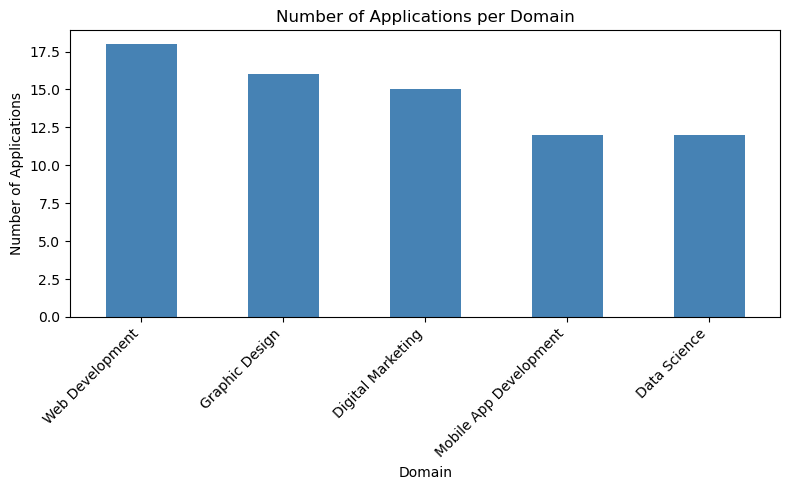

In [12]:
plt.figure(figsize=(8,5)) 
domain_counts.plot(kind='bar', color='steelblue') 
plt.title('Number of Applications per Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applications') 
plt.xticks(rotation=45, ha='right') 
plt.tight_layout() 
plt.show() 

### Chart Explanation

- **Title:** "Number of Applications per Domain" describes the number of applications received for each domain.
- **X-axis:** Represents the different internship domains, including Web Development, Graphic Design, Digital Marketing, Mobile App Development, and Data Science.
- **Y-axis:** Represents the number of applications received for each domain.
- **X-axis Labels:** The domain names are rotated 45 degrees and aligned to the right to make them easier to read and prevent overlapping.

### Key Takeaway

Web Development received the highest number of applications (18), followed by Graphic Design (16) and Digital Marketing (15). Mobile App Development and Data Science received the lowest number of applications, with 12 each.

## How Did Applications Trend Over Time? 

In [15]:
# Group by month 
df['Application Month'] = df['Application Date'].dt.to_period('M') 
monthly_trend = df.groupby('Application Month').size() 
print(monthly_trend) 

Application Month
2026-01     1
2026-03     1
2026-04     3
2026-05     2
2026-06     2
2026-07     1
2026-08    27
2026-09    24
2026-10     9
2026-11     2
2026-12     1
Freq: M, dtype: int64


## The visualization (a line chart, ideal for trends over time): 

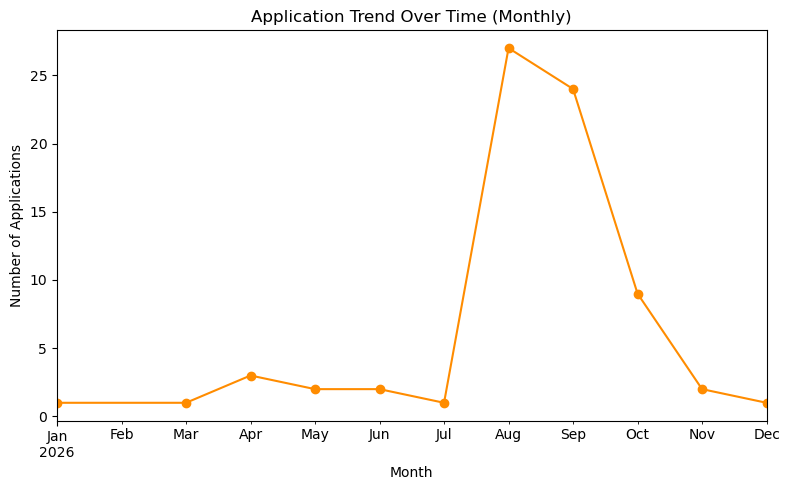

In [16]:
plt.figure(figsize=(8,5)) 
monthly_trend.plot(kind='line', marker='o', color='darkorange') 
plt.title('Application Trend Over Time (Monthly)') 
plt.xlabel('Month') 
plt.ylabel('Number of Applications') 
plt.tight_layout() 
plt.show() 

### Key Takeaway

Applications increased significantly in August 2026, reaching a peak of 27, followed by 24 applications in September. The number then declined to 9 in October, suggesting that most applications were submitted during August and September.

 ## What's the Acceptance Rate — Overall and Per Domain? 

**Overall status breakdown:** 

In [26]:
status_counts = df['Status'].value_counts() 
print(status_counts) 

Status
Under Review    34
Selected        23
Rejected        16
Name: count, dtype: int64


**Per-domain breakdown using pivot_table():**

In [27]:
status_by_domain = pd.pivot_table(     
    df,      
    index='Domain Applied',     
    columns='Status',     
    values='Applicant Name',     
    aggfunc='count',     
    fill_value=0 ) 
print(status_by_domain) 

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Data Science                   2         5             5
Digital Marketing              3         5             7
Graphic Design                 2         6             8
Mobile App Development         4         3             5
Web Development                5         4             9


**Calculate acceptance rate (percentage), not just raw counts:**

In [28]:
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100 
print(status_by_domain_pct.round(1)) 

Status                  Rejected  Selected  Under Review
Domain Applied                                          
Data Science                16.7      41.7          41.7
Digital Marketing           20.0      33.3          46.7
Graphic Design              12.5      37.5          50.0
Mobile App Development      33.3      25.0          41.7
Web Development             27.8      22.2          50.0


## The visualization (a pie chart for overall status, and a stacked/grouped bar chart for perdomain):

**Overall status - pie chart**

Text(0, 0.5, '')

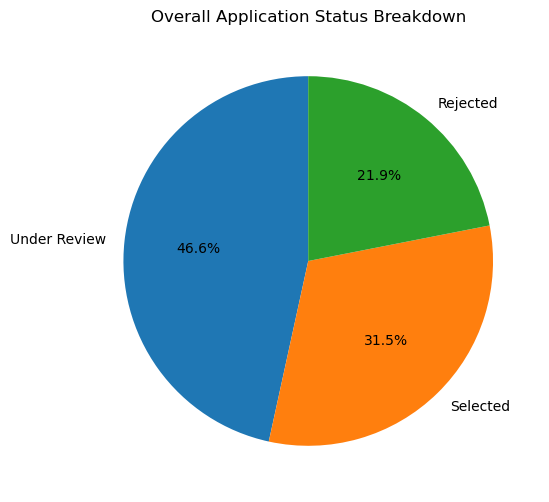

In [29]:
plt.figure(figsize=(6,6)) 
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90) 
plt.title('Overall Application Status Breakdown') 
plt.ylabel('')  # removes the default awkward y-label pie charts add plt.tight_layout() plt.show() 

**Per-domain - grouped bar chart**

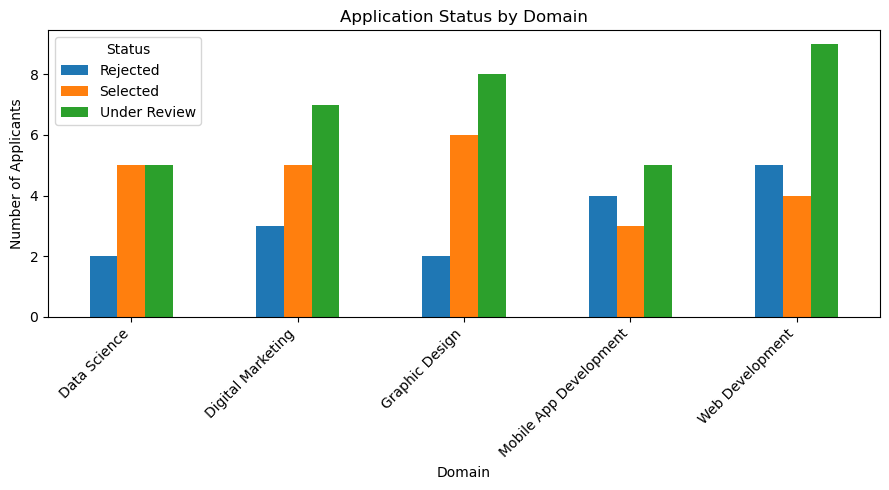

In [30]:
status_by_domain.plot(kind='bar', figsize=(9,5)) 
plt.title('Application Status by Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applicants') 
plt.xticks(rotation=45, ha='right') 
plt.legend(title='Status') 
plt.tight_layout() 
plt.show() 

### Charts Explanation

**1. Bar Chart: Application Status by Domain**

This bar chart compares the number of rejected, selected, and under-review applicants across different internship domains. Web Development has the highest number of applicants under review (9) as well as the highest number of rejected applicants (5), while Graphic Design has the highest number of selected applicants (6).
**2. Pie Chart: Overall Application Status Breakdown**

The pie chart shows the overall distribution of application statuses:
- **Under Review:** 34 applicants
- **Selected:** 23 applicants
- **Rejected:** 16 applicants

### Key Takeaway

Most applications (34) are still under review, while 23 applicants have been selected and 16 have been rejected. Graphic Design has the highest number of selected applicants (6), whereas Web Development has the highest number of applicants under review (9).

## Which Universities Sent the Most Applicants? 


In [33]:
top_universities = df['University'].value_counts().head(10) 
print(top_universities) 

University
Punjab University                                 17
COMSATS University                                13
The University of Faisalabad                      12
University of Sargodha                             9
University of Lahore                               9
Government College University Faisalabad           5
National University of Sciences and Technology     5
Not Specified                                      3
Name: count, dtype: int64


## The visualization (a horizontal bar chart — better than vertical when labels are long university names):

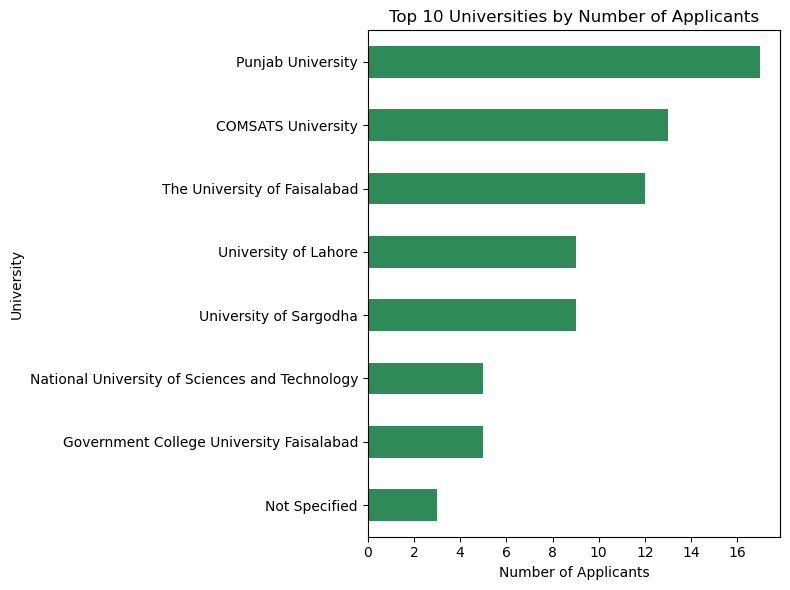

In [34]:
plt.figure(figsize=(8,6)) 
top_universities.sort_values().plot(kind='barh', color='seagreen') 
plt.title('Top 10 Universities by Number of Applicants') 
plt.xlabel('Number of Applicants') 
plt.ylabel('University') 
plt.tight_layout() 
plt.show() 

### Key Takeaway

This dataset represents a total of 73 applicants across 8 university categories. Punjab University accounts for the highest share of applicants (17), followed by COMSATS University (13) and The University of Faisalabad (12). University of Sargodha and University of Lahore each have 9 applicants, while Government College University Faisalabad and National University of Sciences and Technology each have 5, and 3 applicants remain unspecified.

## Bonus Chart: Weekday vs. Weekend Application Activity

### Research Question
Are applicants more active on weekdays or weekends?

### Objective
The objective of this analysis is to compare the number of applications submitted on weekdays (Monday to Friday) with those submitted on weekends (Saturday and Sunday). This will help identify when applicants are more active in submitting their applications.

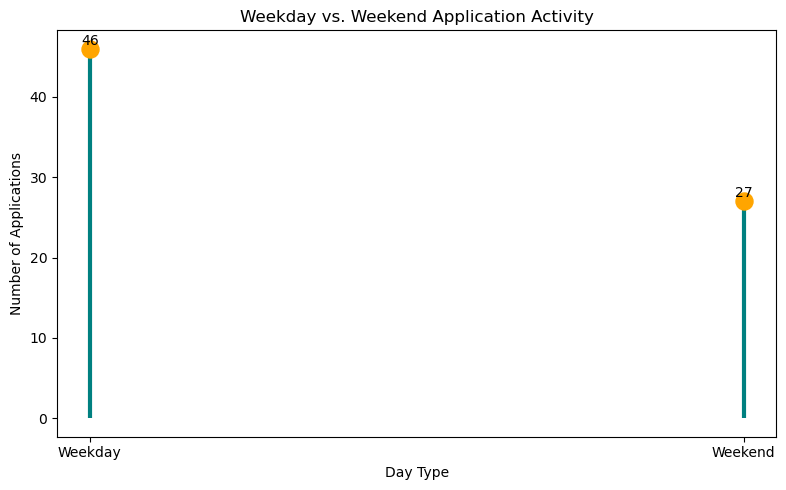

Day Type
Weekday    46
Weekend    27
Name: count, dtype: int64


In [39]:
# Extract day names from application dates
df['Day of Week'] = df['Application Date'].dt.day_name()

# Classify applications into weekdays and weekends
df['Day Type'] = df['Day of Week'].apply(
    lambda day: 'Weekend'
    if day in ['Saturday', 'Sunday']
    else 'Weekday'
)

# Count applications
day_type_counts = df['Day Type'].value_counts().reindex(
    ['Weekday', 'Weekend'], fill_value=0
)

# Create lollipop chart
plt.figure(figsize=(8, 5))

plt.vlines(
    x=day_type_counts.index,
    ymin=0,
    ymax=day_type_counts.values,
    color='teal',
    linewidth=3
)

plt.scatter(
    day_type_counts.index,
    day_type_counts.values,
    color='orange',
    s=150,
    zorder=3
)

# Add count labels
for x, y in zip(day_type_counts.index, day_type_counts.values):
    plt.text(x, y + 0.5, str(y), ha='center')

plt.title('Weekday vs. Weekend Application Activity')
plt.xlabel('Day Type')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()

# Display counts
print(day_type_counts)

### Reason for Choosing This Chart

I chose this analysis to investigate whether applicants are more active in submitting applications on weekdays or weekends. A lollipop chart provides a clear visual comparison of application activity between these two categories.

 ## The "Key Insights" Section:

## Key Insights
- **Web Development** is the most popular domain, receiving the highest application volume (18 applications), nearly 1.5x more than Data Science and Mobile App Development (12 applications each).
- **Application activity** peaked sharply during August (27 applications) and September 2026 (24 applications), indicating that outreach and promotional campaigns were most successful during this late-summer recruitment window.
- **Selection rates** vary significantly by domain; for instance, Data Science achieved the highest selection rate at 41.7% (5 selections out of 12 applicants), whereas Web Development experienced a lower selection rate of 22.2% due to heavier applicant competition.
- **Application statuses** overall show that a large portion of submissions (34 out of 73) remain under review, with 23 candidates selected and 16 rejected, providing a clear operational baseline for managing reviewer workloads moving forward.